# Frota Pulse — Sprint 2: inteligência e diagnóstico

Demonstração passo a passo do pipeline, das fontes brutas ao diagnóstico. **Dados simulados** de três frotas fictícias; nenhum dado real de clientes da Sem Parar Empresas.

O mesmo fluxo roda por linha de comando com `python src/executar_pipeline.py`.

In [1]:
import sys, pandas as pd
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ / 'src'))
from frota_pulse import ingestao, normalizacao, qualidade, integracao, indicadores, benchmark, diagnostico, modelo
pd.set_option('display.max_columns', 20); pd.set_option('display.width', 160)

## 1. Ingestão: CSV, TXT e JSON
Cada arquivo é lido como texto, sem converter nada. Todo registro guarda o arquivo e a linha de origem.

In [2]:
lotes = ingestao.ingerir()
ingestao.resumo(lotes)

,arquivo,fonte,formato,registros,linhas_rejeitadas,hash_sha256
0,data/raw/cadastro/cadastro_frota.csv,cadastro,csv,79,0,1d6004bade98
1,data/raw/combustivel/abastecimentos_cartao.csv,combustivel,csv,7737,0,169b4bb9c9fa
2,data/raw/combustivel/abastecimentos_cartao_ree...,combustivel,csv,161,0,786fcc9ea981
3,data/raw/combustivel/notas_fiscais_combustivel...,nfe_combustivel,json,40,0,0ffda8b3627e
4,data/raw/pedagio/extrato_tag_EMP-A.txt,pedagio,txt,243,0,003b8f52cc76
5,data/raw/pedagio/extrato_tag_EMP-B.txt,pedagio,txt,8345,0,479ff7ead157
6,data/raw/pedagio/extrato_tag_EMP-C.txt,pedagio,txt,3311,1,2279568e95c8
7,data/raw/manutencao/ordens_servico.json,manutencao,json,1540,0,c1be584ef5c5
8,data/raw/multas/notificacoes_multas.json,multas,json,72,0,d8aba4e66166
9,data/raw/financeiro/lancamentos_erp.csv,financeiro,csv,977,0,583411cd9745


Exemplo: uma linha do extrato de pedágio (TXT) como foi lida.

In [3]:
next(l for l in lotes if l.fonte == 'pedagio').dados.head(3)

,_arquivo,_linha,transacao,data_hora,veiculo,concessionaria,praca,eixos,pagador,valor
0,data/raw/pedagio/extrato_tag_EMP-A.txt,5,DSP-A-000068,01/10/2025 17:30,A-V07,CONC-07,PRACA-A07,2,PROPRIO,"R$ 17,09"
1,data/raw/pedagio/extrato_tag_EMP-A.txt,6,DSP-A-000062,02/10/2025 11:27,A-V06,CONC-04,PRACA-A04,2,PROPRIO,"R$ 17,52"
2,data/raw/pedagio/extrato_tag_EMP-A.txt,7,DSP-A-000076,03/10/2025 06:47,A-V07,CONC-02,PRACA-A09,2,PROPRIO,"R$ 12,46"


## 2. Normalização
Colunas, categorias, datas, competência e unidades padronizadas (metros viram km; 'R$ 22,06' vira 22.06).

In [4]:
tabelas = normalizacao.normalizar(lotes)
tabelas['custos'].groupby(['fonte', 'categoria']).valor_brl.agg(['count', 'sum']).round(2)

count          sum
fonte           categoria                      
combustivel     COMBUSTIVEL   7898  13116724.78
financeiro      IMPOSTOS       561    697858.48
                OUTROS         285   1124971.82
                PEDAGIO        131     50234.28
manutencao      MANUTENCAO     770   3838125.08
multas          MULTAS          72     11076.95
nfe_combustivel COMBUSTIVEL     40     82171.57
pedagio         PEDAGIO      11897   1819411.98

## 3. Qualidade
Nada é apagado: cada problema vira uma linha no relatório, com tratamento e justificativa.

In [5]:
tratadas, ocorrencias = qualidade.verificar(lotes, tabelas)
ocorrencias.groupby(['regra', 'descricao_tipo', 'tratamento']).size().rename('ocorrencias')

regra  descricao_tipo                    tratamento
Q00    Linha ilegível                    REJEITADO       1
Q01    Registro duplicado                EXCLUIDO      163
Q02    Registro duplicado                EXCLUIDO       40
Q03    Campo obrigatório vazio           QUARENTENA      4
Q04    Veículo inexistente no cadastro   QUARENTENA      5
Q05    Data inválida                     QUARENTENA      8
Q06    Valor negativo indevido           QUARENTENA      2
Q07    Valor incompatível com a unidade  CORRIGIDO       7
Q08    Valor incompatível com a unidade  CORRIGIDO       5
Q09    Campo obrigatório vazio           IMPUTADO       20
Q11    Dado incoerente                   QUARENTENA      2
Q12    Dado incoerente                   ALERTA          6
Q13    Registro duplicado                ALERTA         15
Q14    Campo obrigatório vazio           ALERTA         21
Q15    Valor incompatível com a unidade  QUARENTENA      1
       Valor negativo indevido           QUARENTENA      1
Q16 

In [6]:
ocorrencias[ocorrencias.regra.isin(['Q07', 'Q04', 'Q15'])][['regra', 'arquivo', 'linha', 'registro', 'valor_encontrado', 'tratamento', 'justificativa']].head(6)

,regra,arquivo,linha,registro,valor_encontrado,tratamento,justificativa
208,Q04,data/raw/combustivel/abastecimentos_cartao.csv,48,DSP-C-000754,C-V99,QUARENTENA,"Veículo ausente do cadastro (agregado, cartão ..."
209,Q04,data/raw/combustivel/abastecimentos_cartao.csv,2017,DSP-C-003018,C-V99,QUARENTENA,"Veículo ausente do cadastro (agregado, cartão ..."
210,Q04,data/raw/combustivel/abastecimentos_cartao.csv,2282,DSP-C-002581,C-V99,QUARENTENA,"Veículo ausente do cadastro (agregado, cartão ..."
211,Q04,data/raw/combustivel/abastecimentos_cartao.csv,6551,DSP-C-008290,C-V99,QUARENTENA,"Veículo ausente do cadastro (agregado, cartão ..."
212,Q04,data/raw/manutencao/ordens_servico.json,420,DSP-B-005675,B-V99,QUARENTENA,"Veículo ausente do cadastro (agregado, cartão ..."
223,Q07,data/raw/combustivel/abastecimentos_cartao.csv,2262,DSP-C-002892,62.13,CORRIGIDO,Preço com casa decimal deslocada; corrigido po...


## 4. Integração: base veículo-mês
Cadastro, custos rateados por competência, quilometragem e telemetria do ESP32, pela chave veículo + mês.

In [7]:
integ = integracao.integrar(tratadas)
base = integ['base_mensal']
base[['veiculo_id', 'competencia', 'grupo', 'custo_combustivel', 'custo_manutencao', 'custo_total', 'km', 'litros', 'pct_rpm_acima_verde', 'pct_marcha_lenta']].head()

,veiculo_id,competencia,grupo,custo_combustivel,custo_manutencao,custo_total,km,litros,pct_rpm_acima_verde,pct_marcha_lenta
0,A-V01,2025-10,LEVE_URBANA_UTILITARIO,2140.00,0.00,2215.54,2879.8,334.41,1.8,6.7
1,A-V01,2025-11,LEVE_URBANA_UTILITARIO,1865.64,0.00,2032.58,2655.7,295.24,5.8,13.3
2,A-V01,2025-12,LEVE_URBANA_UTILITARIO,1494.89,0.00,1553.71,2150.4,235.75,9.4,11.7
3,A-V01,2026-01,LEVE_URBANA_UTILITARIO,1705.83,2640.02,4428.14,2306.6,268.40,3.7,10.0
4,A-V01,2026-02,LEVE_URBANA_UTILITARIO,1583.21,0.00,1660.66,2228.3,245.56,0.0,13.3


## 5. Indicadores
Custo por km = custo dos meses com km ÷ km; consumo = km ÷ litros; participação = categoria ÷ total × 100.

In [8]:
v = indicadores.por_veiculo(base)
v[['veiculo_id', 'nome_grupo', 'km_total', 'custo_total', 'custo_km', 'km_l', 'preco_medio_l', 'part_combustivel_pct', 'part_manutencao_pct']].round(3).head(8)

,veiculo_id,nome_grupo,km_total,custo_total,custo_km,km_l,preco_medio_l,part_combustivel_pct,part_manutencao_pct
0,A-V01,Leve urbana (utilitário),14535.2,13757.68,0.947,8.790,6.381,76.70,19.19
1,A-V02,Leve urbana (utilitário),NaN,9094.93,NaN,NaN,6.514,94.48,0.00
2,A-V03,Leve urbana (utilitário),NaN,9241.17,NaN,NaN,6.407,91.68,0.00
3,A-V04,Leve urbana (utilitário),NaN,10049.28,NaN,NaN,6.361,78.37,16.22
4,A-V05,Leve urbana (automóvel),9004.8,5914.79,0.657,10.936,6.566,91.40,0.00
5,A-V06,Leve urbana (automóvel),8173.5,5609.22,0.686,11.356,6.507,83.49,11.25
6,A-V07,Leve urbana (automóvel),10205.1,26823.25,2.628,11.639,6.467,21.14,0.00
7,A-V08,Leve urbana (automóvel),8444.2,25635.59,3.036,12.347,6.436,17.17,0.00


## 6. Benchmark por grupo comparável
Mediana como referência; média e quartis para mostrar a dispersão.

In [9]:
est = benchmark.estatisticas(v)
est[est.indicador.isin(['custo_km', 'km_l'])][['nome_grupo', 'indicador', 'n', 'media', 'mediana', 'q1', 'q3', 'referencia_valida']].round(3)

,nome_grupo,indicador,n,media,mediana,q1,q3,referencia_valida
0,Leve mista (utilitário),custo_km,8,1.926,1.410,1.348,2.646,True
1,Leve mista (utilitário),km_l,8,9.295,9.335,9.203,9.428,True
9,Leve urbana (automóvel),custo_km,2,0.672,0.672,0.664,0.679,False
10,Leve urbana (automóvel),km_l,4,11.570,11.498,11.251,11.816,False
18,Leve urbana (utilitário),custo_km,1,0.947,0.947,0.947,0.947,False
19,Leve urbana (utilitário),km_l,1,8.790,8.790,8.790,8.790,False
27,Média mista (caminhão toco),custo_km,12,2.160,2.145,2.111,2.255,True
28,Média mista (caminhão toco),km_l,12,4.565,4.582,4.402,4.740,True
36,Média mista (VUC),custo_km,10,1.891,1.855,1.746,2.016,True
37,Média mista (VUC),km_l,10,6.268,6.359,5.855,6.620,True


## 7. Gap de eficiência
Positivo = pior que a referência. Custo: (veículo − referência) ÷ referência. Consumo: (referência − veículo) ÷ referência.

In [10]:
g = benchmark.gaps(v, est)
benchmark.ranking(g, 'custo_km', 8).round(3)

,veiculo_id,nome_grupo,custo_km,ref_custo_km,gap_custo_km,gap_custo_km_pct
0,B-V28,Leve mista (utilitário),3.130,1.410,1.719,121.895
1,B-V29,Leve mista (utilitário),2.993,1.410,1.583,112.224
2,B-V30,Leve mista (utilitário),2.530,1.410,1.119,79.366
3,B-V02,Média mista (VUC),2.203,1.855,0.348,18.747
4,C-V30,Pesada rodoviária (truck),2.933,2.535,0.397,15.677
5,B-V01,Média mista (VUC),2.143,1.855,0.288,15.537
6,C-V38,Pesada rodoviária (truck),2.880,2.535,0.345,13.607
7,C-V10,Pesada rodoviária (cavalo mecânico),4.158,3.694,0.464,12.561


In [11]:
benchmark.ranking(g, 'km_l', 8).round(3)

,veiculo_id,nome_grupo,km_l,ref_km_l,gap_km_l,gap_km_l_pct
0,C-V33,Pesada rodoviária (truck),3.072,3.555,0.483,13.578
1,C-V30,Pesada rodoviária (truck),3.103,3.555,0.452,12.722
2,B-V19,Média mista (caminhão toco),4.002,4.582,0.580,12.660
3,C-V38,Pesada rodoviária (truck),3.121,3.555,0.434,12.198
4,C-V32,Pesada rodoviária (truck),3.173,3.555,0.382,10.748
5,B-V06,Média mista (VUC),5.705,6.359,0.654,10.289
6,B-V02,Média mista (VUC),5.726,6.359,0.633,9.952
7,C-V07,Pesada rodoviária (cavalo mecânico),2.156,2.391,0.235,9.833


## 8. Diagnóstico por regras
Eficiente ≤ 5% < Atenção ≤ 15% < Ineficiente, sobre o pior gap entre custo por km e consumo.

In [12]:
diag = diagnostico.classificar(g)
diagnostico.resumo(diag)

nivel_regras,Eficiente,Atenção,Ineficiente,Sem referência
nome_grupo,,,,
Leve mista (utilitário),5,0,3,0
Leve urbana (automóvel),0,0,0,4
Leve urbana (utilitário),0,0,0,4
Média mista (VUC),6,2,2,0
Média mista (caminhão toco),6,6,0,0
Pesada rodoviária (cavalo mecânico),19,9,0,0
Pesada rodoviária (truck),8,3,1,0


In [13]:
diag[diag.nivel_regras == 'Ineficiente'][['veiculo_id', 'nome_grupo', 'pior_gap_pct', 'justificativa']]

,veiculo_id,nome_grupo,pior_gap_pct,justificativa
8,B-V01,Média mista (VUC),15.537447,"custo por km +15,5% em relação à mediana do gr..."
9,B-V02,Média mista (VUC),18.747403,"custo por km +18,7% em relação à mediana do gr..."
35,B-V28,Leve mista (utilitário),121.895371,"custo por km +121,9% em relação à mediana do g..."
36,B-V29,Leve mista (utilitário),112.223859,"custo por km +112,2% em relação à mediana do g..."
37,B-V30,Leve mista (utilitário),79.366452,"custo por km +79,4% em relação à mediana do gr..."
67,C-V30,Pesada rodoviária (truck),15.677224,"custo por km +15,7% em relação à mediana do gr..."


## 9. Modelo supervisionado
Rótulo: consumo do mês mais de 5% pior que o grupo. Atributos: só telemetria e idade. Separação por veículo (sem vazamento).

In [14]:
mensal = diagnostico.classificar_mensal(benchmark.gaps_mensais(indicadores.por_veiculo_mes(base), v))
res = modelo.treinar(mensal, 'consumo')
print(res['tamanhos'])
print('linha de base no teste:', res['linha_de_base_teste'])
pd.DataFrame({k: m['teste'] for k, m in res['comparacao_modelos'].items()}).T

{'veiculo_meses': 835, 'treino': 585, 'teste': 250, 'veiculos_treino': 49, 'veiculos_teste': 21, 'taxa_ineficiente_treino': 0.263, 'taxa_ineficiente_teste': 0.264}
linha de base no teste: 0.736


,acuracia,acuracia_balanceada,precisao_ineficiente,recall_ineficiente,f1_ineficiente
arvore_decisao,0.828,0.796,0.658,0.727,0.691
regressao_logistica,0.848,0.843,0.671,0.833,0.743
floresta_aleatoria,0.832,0.832,0.640,0.833,0.724


In [15]:
print(res['regras_arvore'])

|--- pct_marcha_lenta <= 10.8
|   |--- pct_excesso_velocidade <= 7.5
|   |   |--- pct_rpm_acima_verde <= 28.4
|   |   |   |--- class: 0
|   |   |--- pct_rpm_acima_verde >  28.4
|   |   |   |--- class: 0
|   |--- pct_excesso_velocidade >  7.5
|   |   |--- idade_anos <= 6.5
|   |   |   |--- class: 1
|   |   |--- idade_anos >  6.5
|   |   |   |--- class: 0
|--- pct_marcha_lenta >  10.8
|   |--- pct_rpm_acima_verde <= 30.3
|   |   |--- pct_marcha_lenta <= 15.9
|   |   |   |--- class: 0
|   |   |--- pct_marcha_lenta >  15.9
|   |   |   |--- class: 1
|   |--- pct_rpm_acima_verde >  30.3
|   |   |--- grupo_LEVE_MISTA_UTILITARIO <= 0.5
|   |   |   |--- class: 1
|   |   |--- grupo_LEVE_MISTA_UTILITARIO >  0.5
|   |   |   |--- class: 0



In [16]:
modelo.exemplos(res)[['veiculo_id', 'competencia', 'rotulo', 'previsao_ml', 'resultado', 'gap_km_l_pct', 'pct_marcha_lenta', 'pct_rpm_acima_verde', 'pct_excesso_velocidade']].round(1)

,veiculo_id,competencia,rotulo,previsao_ml,resultado,gap_km_l_pct,pct_marcha_lenta,pct_rpm_acima_verde,pct_excesso_velocidade
0,B-V08,2025-07,0,0,correta,1.0,1.7,10.2,0.0
1,B-V08,2025-10,0,0,correta,0.5,6.7,17.9,1.7
2,B-V08,2026-03,0,0,correta,-1.9,8.3,16.4,1.7
3,B-V05,2025-07,1,1,correta,7.8,11.7,35.8,6.7
4,B-V05,2025-12,1,1,correta,10.4,13.3,38.5,5.0
5,B-V05,2026-02,1,1,correta,8.5,18.3,37.5,8.3
6,B-V05,2025-10,0,1,incorreta,4.4,16.7,20.0,1.7
7,B-V09,2025-08,0,1,incorreta,-5.8,20.0,20.8,0.0
8,B-V20,2025-11,0,1,incorreta,-6.5,16.7,24.0,3.3
9,B-V05,2026-06,1,0,incorreta,11.1,10.0,35.8,10.0


## 10. Regras x modelo
Nos veículos de teste: onde concordam e onde divergem.

In [17]:
cmp_, _ = modelo.comparar_com_regras(res, diag)
cmp_[['veiculo_id', 'nivel_regras', 'leitura_ml', 'concordam', 'interpretacao']]

,veiculo_id,nivel_regras,leitura_ml,concordam,interpretacao
0,B-V05,Atenção,Condução ineficiente,True,Concordam: desvio com componente de condução; ...
1,B-V08,Eficiente,Condução dentro do padrão,True,Concordam: dentro da referência nas duas leituras
2,B-V09,Eficiente,Condução dentro do padrão,True,Concordam: dentro da referência nas duas leituras
3,B-V12,Atenção,Condução dentro do padrão,False,"Divergem: as regras apontam desvio, mas a tele..."
4,B-V14,Eficiente,Condução dentro do padrão,True,Concordam: dentro da referência nas duas leituras
5,B-V15,Atenção,Condução ineficiente,True,Concordam: desvio com componente de condução; ...
6,B-V20,Eficiente,Condução dentro do padrão,True,Concordam: dentro da referência nas duas leituras
7,B-V23,Eficiente,Condução dentro do padrão,True,Concordam: dentro da referência nas duas leituras
8,B-V29,Ineficiente,Condução dentro do padrão,False,"Divergem: as regras apontam desvio, mas a tele..."
9,C-V03,Atenção,Condução ineficiente,True,Concordam: desvio com componente de condução; ...


## Gráficos gerados pelo pipeline

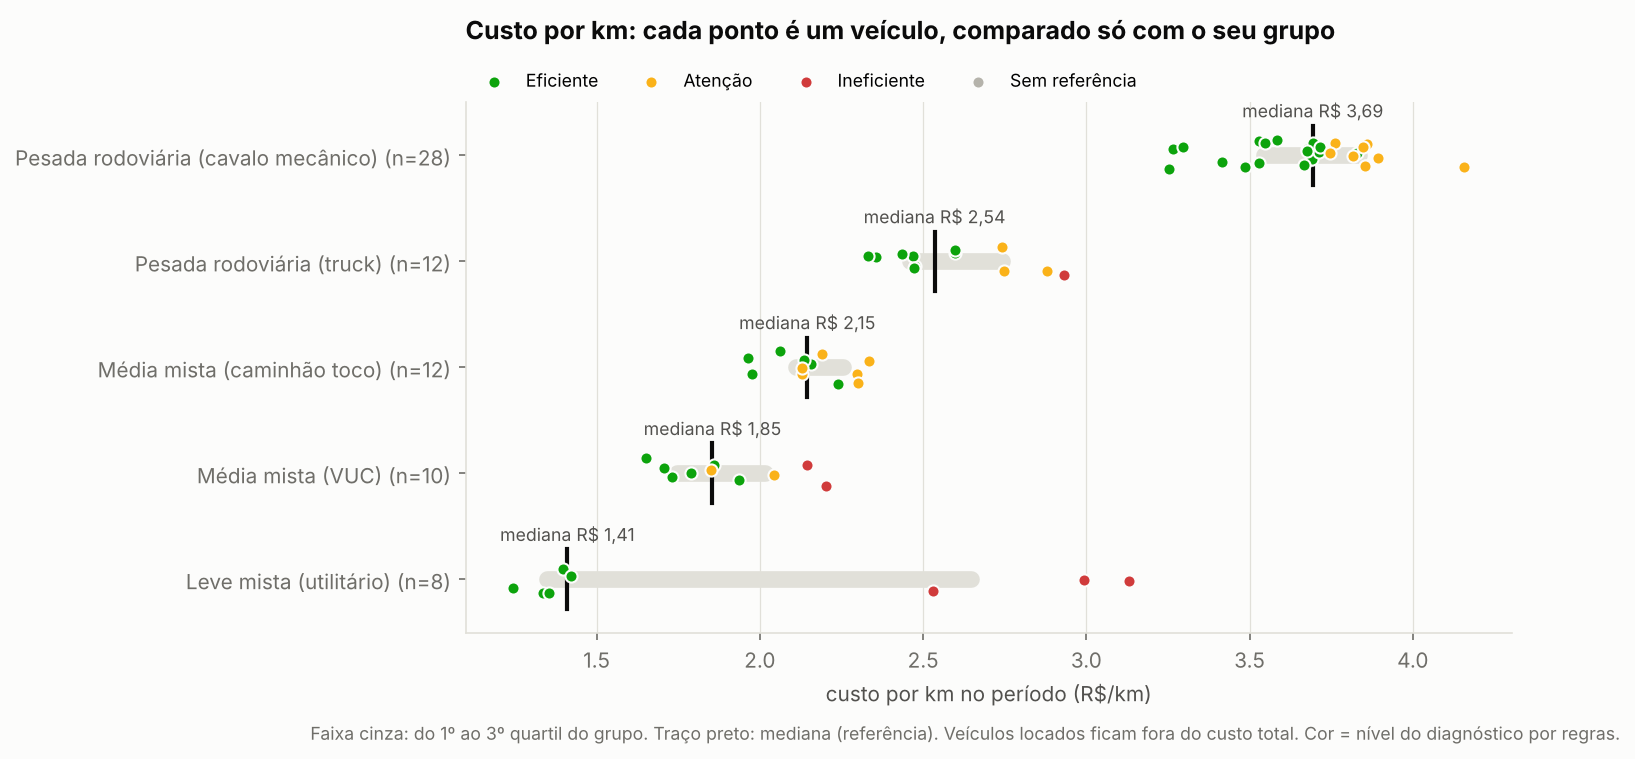

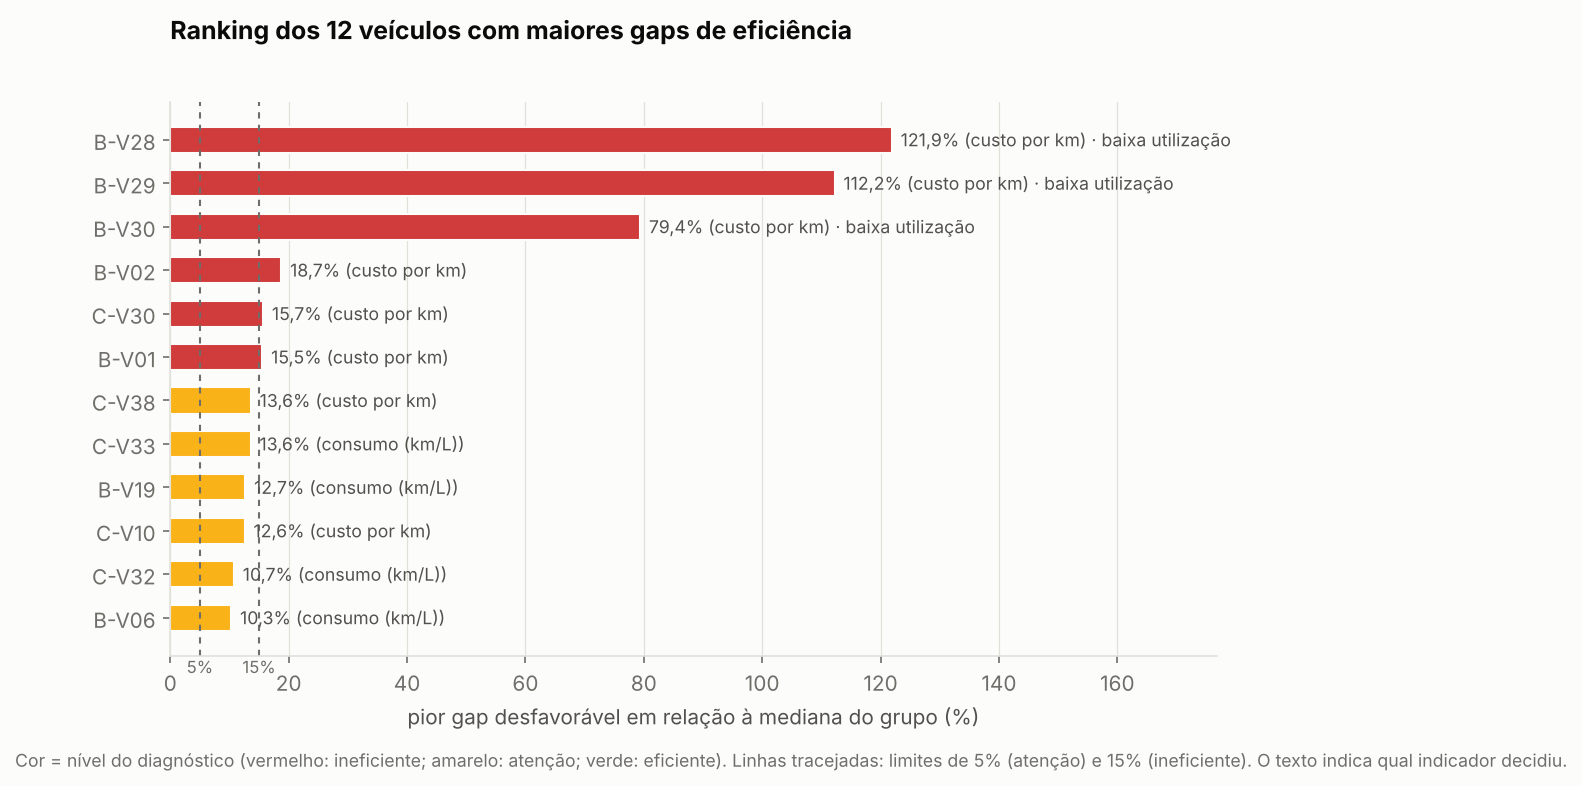

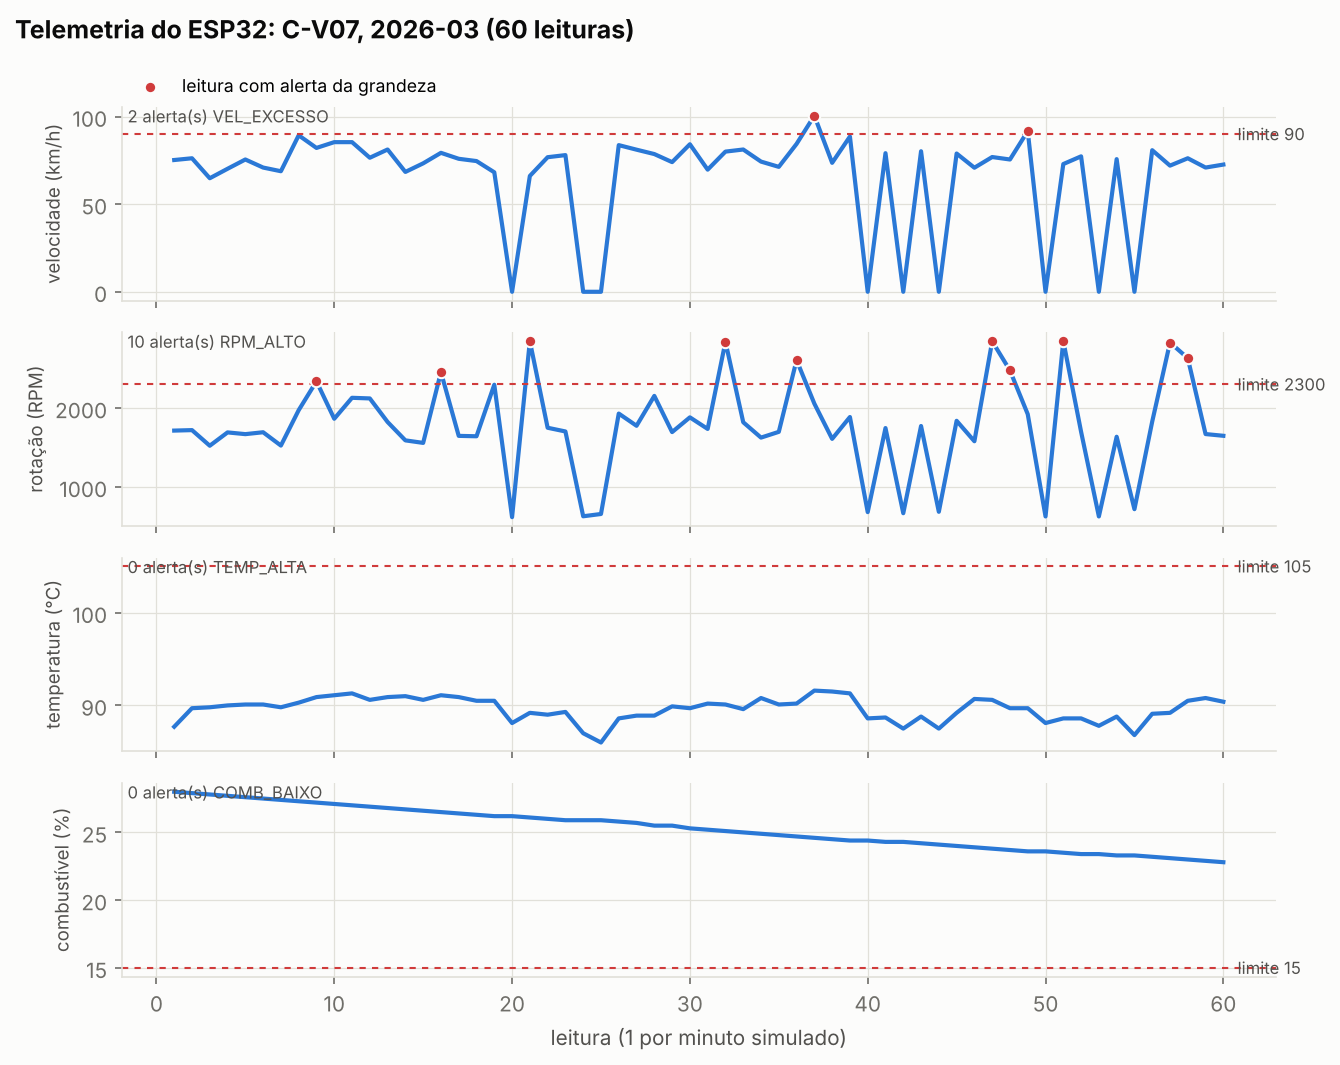

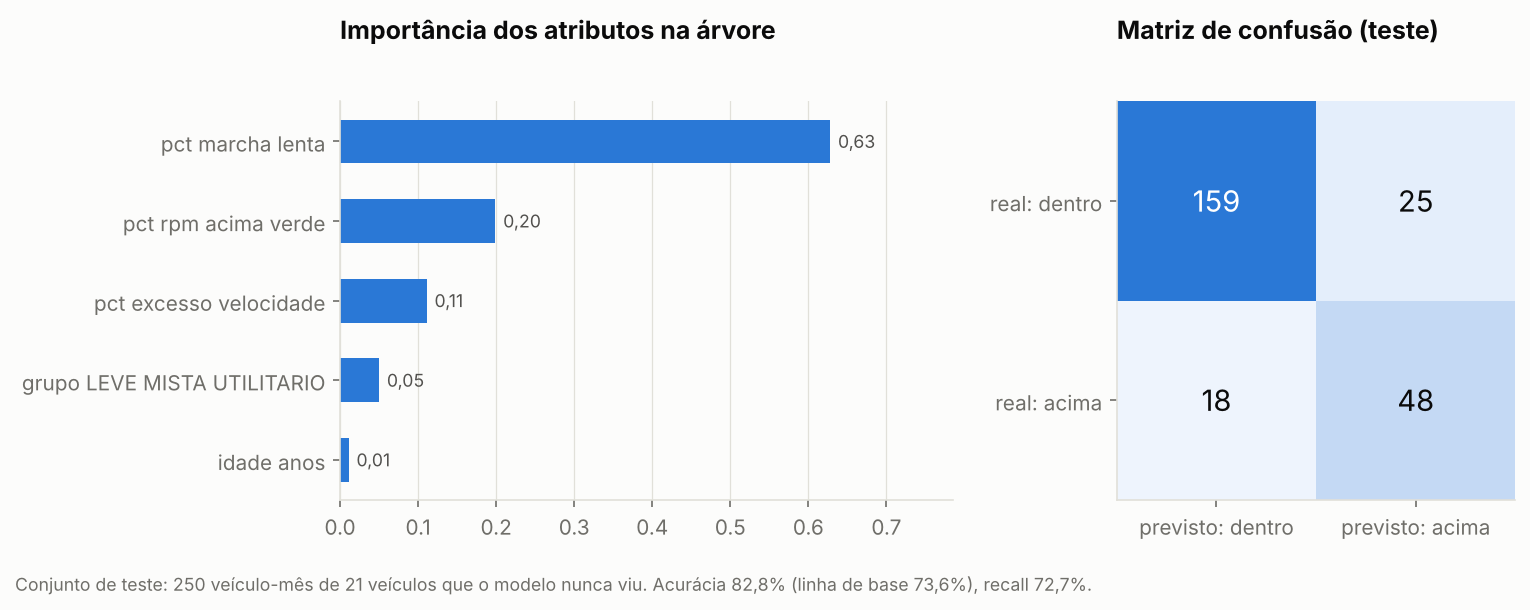

In [18]:
from IPython.display import Image, display
for nome in ['02_custo_km_por_grupo', '03_ranking_gaps', '06_telemetria_C-V07', '07_modelo_arvore']:
    display(Image(filename=str(RAIZ / 'outputs' / 'charts' / f'{nome}.png'), width=900))

**Limitações:** dados simulados; grupos pequenos; a relação entre telemetria e consumo foi construída na simulação. Detalhes em `docs/`.